# Riesgo de incumplimiento de crédito para pymes

**Asignatura:** Aprendizaje de Máquina Supervisado  
**Grupo:** 4  
**Integrantes:** Nicolás Carvajal, Luis Ortega y Santiago Garzón  
**Modelos estudiados:** árboles de decisión y máquinas de soporte vectorial

En este notebook se estudia el riesgo de incumplimiento de una pyme. El objetivo no es quedarse solamente con la exactitud, sino revisar cómo cambia cada modelo cuando se controla su complejidad.


## 1. Metodología

Se seguirá el orden de la guía:

1. Revisión del conjunto de datos.
2. Cálculo manual de impureza para los cortes 45.91 y 58.77 de `endeudamiento_pct`.
3. Árboles sin restricciones y comparación entre Gini y entropía.
4. Experimentos de pre-poda, número máximo de hojas y poda con `ccp_alpha`.
5. SVM lineal, polinomial y RBF.
6. Comparación final y selección de un modelo.

Los parámetros se cambian de forma explícita. No se utiliza `GridSearchCV` ni una búsqueda automática.

In [14]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

RANDOM_STATE = 42

## 2. Carga y revisión de los datos

El archivo se busca primero en la misma carpeta del notebook y luego en la carpeta de Descargas. Esto permite mover el notebook junto con el CSV sin tener que cambiar el código.

In [11]:
import pandas as pd
df = pd.read_csv('grupo04_riesgo_credito_pyme.csv')

display(df.head())

,id_empresa,endeudamiento_pct,liquidez_corriente,antiguedad_empresa_anios,variabilidad_caja_pct,pagos_atrasados_12m,incumplimiento
0,1,59.13,1.751,9.64,26.21,4,0
1,2,40.91,1.809,5.01,27.44,3,0
2,3,60.22,3.500,10.39,29.07,3,0
3,4,68.07,0.720,10.66,8.49,3,0
4,5,57.39,1.557,6.05,9.76,4,1


In [12]:
resumen_datos = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "faltantes": df.isna().sum(),
    "valores_unicos": df.nunique(),
})
display(resumen_datos)
display(df.describe().T)

duplicados = int(df.duplicated().sum())
print(f"Registros duplicados: {duplicados}")
print("Distribución de la variable objetivo:")
display(df["incumplimiento"].value_counts().sort_index().rename("cantidad").to_frame())

,tipo,faltantes,valores_unicos
id_empresa,int64,0,240
endeudamiento_pct,float64,0,232
liquidez_corriente,float64,0,215
antiguedad_empresa_anios,float64,0,199
variabilidad_caja_pct,float64,0,223
pagos_atrasados_12m,int64,0,9
incumplimiento,int64,0,2


,count,mean,std,min,25%,50%,75%,max
id_empresa,240.0,120.500000,69.426220,1.00,60.7500,120.500,180.2500,240.00
endeudamiento_pct,240.0,52.202500,17.768839,10.00,39.5525,51.555,64.8075,95.00
liquidez_corriente,240.0,1.234817,0.575016,0.35,0.8320,1.127,1.4600,3.50
antiguedad_empresa_anios,240.0,7.030792,3.975206,0.50,4.2050,6.625,9.9100,16.75
variabilidad_caja_pct,240.0,22.086833,9.557472,3.00,15.7125,22.375,28.9875,49.51
pagos_atrasados_12m,240.0,2.316667,1.615735,0.00,1.0000,2.000,3.0000,9.00
incumplimiento,240.0,0.420833,0.494725,0.00,0.0000,0.000,1.0000,1.00


Registros duplicados: 0
Distribución de la variable objetivo:


,cantidad
incumplimiento,
0,139
1,101


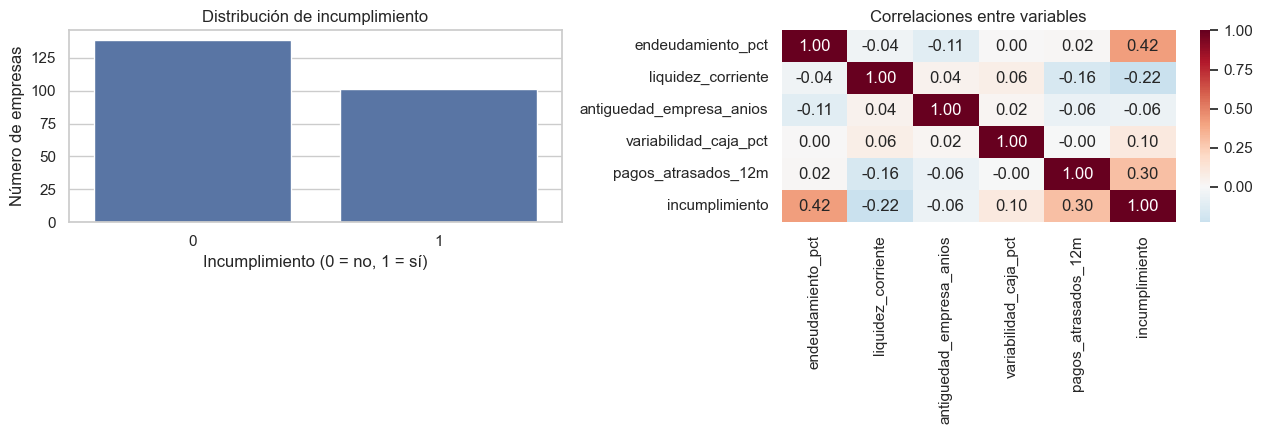

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

conteo_objetivo = df["incumplimiento"].value_counts().sort_index()
sns.barplot(x=conteo_objetivo.index, y=conteo_objetivo.values, ax=axes[0])
axes[0].set_title("Distribución de incumplimiento")
axes[0].set_xlabel("Incumplimiento (0 = no, 1 = sí)")
axes[0].set_ylabel("Número de empresas")

corr = df.drop(columns="id_empresa").corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1])
axes[1].set_title("Correlaciones entre variables")

plt.tight_layout()
plt.show()

La variable `id_empresa` solo identifica cada registro, por lo que no se usa como predictor. La variable que se desea predecir es `incumplimiento`.

In [16]:
X = df.drop(columns=["id_empresa", "incumplimiento"])
y = df["incumplimiento"]

variables = list(X.columns)
print("Variables predictoras:")
for i, nombre in enumerate(variables, start=1):
    print(f"z{i}: {nombre}")

Variables predictoras:
z1: endeudamiento_pct
z2: liquidez_corriente
z3: antiguedad_empresa_anios
z4: variabilidad_caja_pct
z5: pagos_atrasados_12m


## 3. Cálculo manual de impureza

Se comparan dos divisiones candidatas de `endeudamiento_pct`: 45.91 y 58.77. Para cada corte se calculan Gini, entropía y ganancia de información.

Para un nodo con proporciones de clase $p_k$:

$$Gini = 1 - \sum_k p_k^2$$

$$H = -\sum_k p_k \log_2(p_k)$$

La impureza de la división es el promedio ponderado de los nodos hijos. La mejor división es la que deja menor impureza o, de forma equivalente, mayor ganancia.

In [17]:
def gini(serie):
    proporciones = serie.value_counts(normalize=True)
    return 1 - np.sum(proporciones ** 2)


def entropia(serie):
    proporciones = serie.value_counts(normalize=True)
    return -np.sum(proporciones * np.log2(proporciones))


def evaluar_corte(datos, variable, objetivo, corte):
    izquierda = datos.loc[datos[variable] <= corte, objetivo]
    derecha = datos.loc[datos[variable] > corte, objetivo]
    n = len(datos)

    gini_ponderado = (
        len(izquierda) / n * gini(izquierda)
        + len(derecha) / n * gini(derecha)
    )
    entropia_ponderada = (
        len(izquierda) / n * entropia(izquierda)
        + len(derecha) / n * entropia(derecha)
    )

    return {
        "corte": corte,
        "n_izquierda": len(izquierda),
        "incumple_izquierda": int(izquierda.sum()),
        "n_derecha": len(derecha),
        "incumple_derecha": int(derecha.sum()),
        "gini_ponderado": gini_ponderado,
        "ganancia_gini": gini(datos[objetivo]) - gini_ponderado,
        "entropia_ponderada": entropia_ponderada,
        "ganancia_informacion": entropia(datos[objetivo]) - entropia_ponderada,
    }


resultados_cortes = pd.DataFrame([
    evaluar_corte(df, "endeudamiento_pct", "incumplimiento", corte)
    for corte in [45.91, 58.77]
])
display(resultados_cortes)

,corte,n_izquierda,incumple_izquierda,n_derecha,incumple_derecha,gini_ponderado,ganancia_gini,entropia_ponderada,ganancia_informacion
0,45.9100,84,17,156,84,0.4361,0.0514,0.9016,0.0803
1,58.7700,156,43,84,58,0.4092,0.0783,0.8646,0.1173


In [18]:
mejor_corte = resultados_cortes.loc[
    resultados_cortes["ganancia_informacion"].idxmax()
]

display(Markdown(
    f"El corte **{mejor_corte['corte']:.2f}** es el mejor de los dos. "
    f"Su Gini ponderado es **{mejor_corte['gini_ponderado']:.4f}** y su ganancia "
    f"de información es **{mejor_corte['ganancia_informacion']:.4f}**. "
    "Este corte separa mejor a las empresas según su comportamiento de pago."
))

El corte **58.77** es el mejor de los dos. Su Gini ponderado es **0.4092** y su ganancia de información es **0.1173**. Este corte separa mejor a las empresas según su comportamiento de pago.

## 4. División de entrenamiento y prueba

Se utiliza 75 % para entrenamiento y 25 % para prueba, con estratificación. Esta partición se conserva en todos los modelos.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Entrenamiento: {X_train.shape[0]} observaciones")
print(f"Prueba: {X_test.shape[0]} observaciones")
print("Proporción de incumplimiento:")
print(f"  Entrenamiento: {y_train.mean():.3f}")
print(f"  Prueba: {y_test.mean():.3f}")

Entrenamiento: 180 observaciones
Prueba: 60 observaciones
Proporción de incumplimiento:
  Entrenamiento: 0.422
  Prueba: 0.417


# Parte I. Árboles de decisión

## 5. Árboles sin restricciones

Se ajustan dos árboles completos, uno con Gini y otro con entropía. Todavía no se limita la profundidad ni el número de hojas.

In [20]:
def metricas_arbol(modelo, nombre):
    modelo.fit(X_train, y_train)
    return {
        "modelo": nombre,
        "exactitud_train": accuracy_score(y_train, modelo.predict(X_train)),
        "exactitud_test": accuracy_score(y_test, modelo.predict(X_test)),
        "brecha_train_test": (
            accuracy_score(y_train, modelo.predict(X_train))
            - accuracy_score(y_test, modelo.predict(X_test))
        ),
        "profundidad": modelo.get_depth(),
        "hojas": modelo.get_n_leaves(),
    }


arbol_gini = DecisionTreeClassifier(criterion="gini", random_state=RANDOM_STATE)
arbol_entropia = DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE)

tabla_arboles_base = pd.DataFrame([
    metricas_arbol(arbol_gini, "Árbol Gini sin poda"),
    metricas_arbol(arbol_entropia, "Árbol entropía sin poda"),
])
display(tabla_arboles_base)

,modelo,exactitud_train,exactitud_test,brecha_train_test,profundidad,hojas
0,Árbol Gini sin poda,1.0000,0.5833,0.4167,11,43
1,Árbol entropía sin poda,1.0000,0.6333,0.3667,12,41


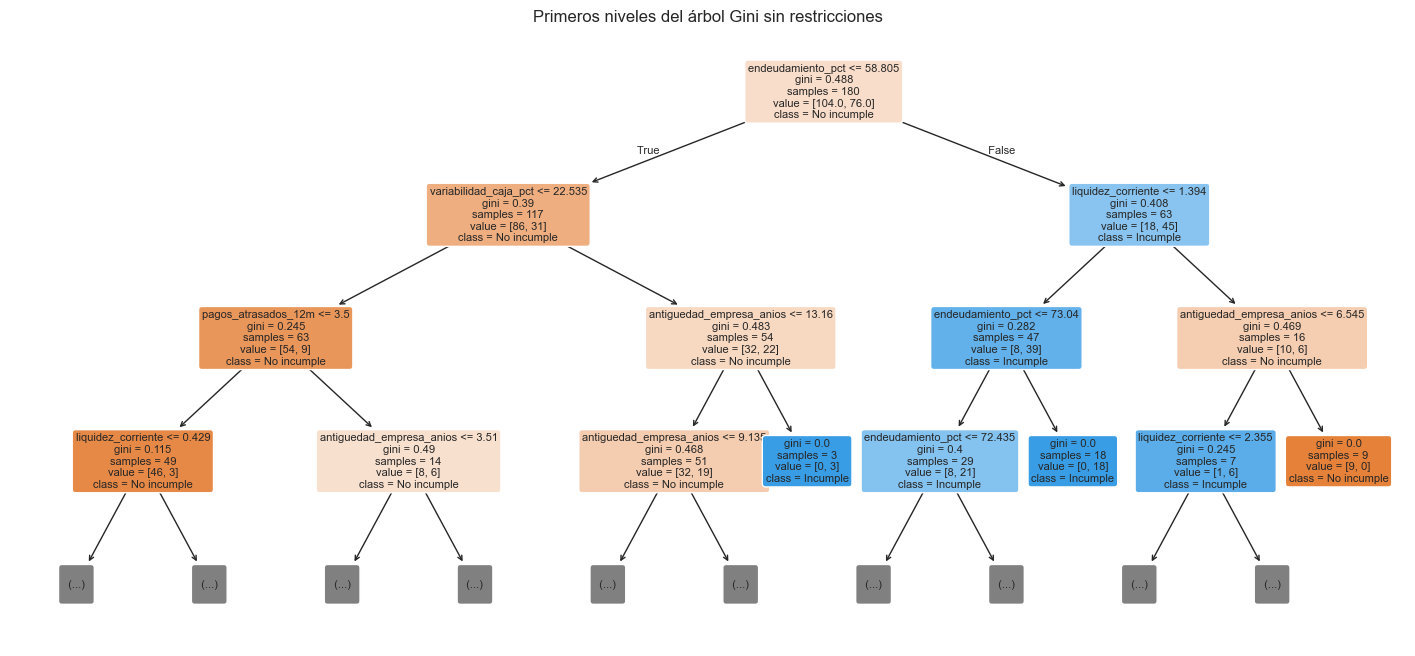

Primeras reglas del árbol:
|--- endeudamiento_pct <= 58.81
|   |--- variabilidad_caja_pct <= 22.53
|   |   |--- pagos_atrasados_12m <= 3.50
|   |   |   |--- truncated branch of depth 6
|   |   |--- pagos_atrasados_12m >  3.50
|   |   |   |--- truncated branch of depth 7
|   |--- variabilidad_caja_pct >  22.53
|   |   |--- antiguedad_empresa_anios <= 13.16
|   |   |   |--- truncated branch of depth 9
|   |   |--- antiguedad_empresa_anios >  13.16
|   |   |   |--- class: 1
|--- endeudamiento_pct >  58.81
|   |--- liquidez_corriente <= 1.39
|   |   |--- endeudamiento_pct <= 73.04
|   |   |   |--- truncated branch of depth 6
|   |   |--- endeudamiento_pct >  73.04
|   |   |   |--- class: 1
|   |--- liquidez_corriente >  1.39
|   |   |--- antiguedad_empresa_anios <= 6.55
|   |   |   |--- truncated branch of depth 2
|   |   |--- antiguedad_empresa_anios >  6.55
|   |   |   |--- class: 0



In [21]:
plt.figure(figsize=(18, 8))
plot_tree(
    arbol_gini,
    feature_names=X.columns,
    class_names=["No incumple", "Incumple"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8,
)
plt.title("Primeros niveles del árbol Gini sin restricciones")
plt.show()

print("Primeras reglas del árbol:")
print(export_text(arbol_gini, feature_names=list(X.columns), max_depth=2, decimals=2))

El árbol completo consigue un ajuste perfecto en entrenamiento, pero baja bastante en prueba. Esta diferencia es una primera señal de sobreajuste. La visualización se limita a los primeros niveles para que las reglas se puedan leer.

## 6. Pre-poda

En cada experimento se modifica un solo parámetro. El resto queda con sus valores predeterminados y se usa Gini para mantener una referencia común.

In [23]:
def experimento_parametro(nombre_parametro, valores):
    filas = []
    for valor in valores:
        parametros = {nombre_parametro: valor}
        modelo = DecisionTreeClassifier(
            criterion="gini",
            random_state=RANDOM_STATE,
            **parametros,
        )
        resultado = metricas_arbol(modelo, str(valor))
        resultado[nombre_parametro] = valor
        filas.append(resultado)
    columnas = [
        nombre_parametro,
        "exactitud_train",
        "exactitud_test",
        "brecha_train_test",
        "profundidad",
        "hojas",
    ]
    return pd.DataFrame(filas)[columnas]


resultados_depth = experimento_parametro("max_depth", [2, 3, 4, 5, None])
resultados_split = experimento_parametro("min_samples_split", [2, 5, 10, 20, 50, 100])
resultados_leaf = experimento_parametro("min_samples_leaf", [1, 2, 5, 10])

print("max_depth")
display(resultados_depth)
print("min_samples_split")
display(resultados_split)
print("min_samples_leaf")
display(resultados_leaf)

max_depth


,max_depth,exactitud_train,exactitud_test,brecha_train_test,profundidad,hojas
0,2.0000,0.7500,0.6833,0.0667,2,4
1,3.0000,0.7944,0.6833,0.1111,3,8
2,4.0000,0.8333,0.6833,0.1500,4,13
3,5.0000,0.8611,0.6833,0.1778,5,18
4,NaN,1.0000,0.5833,0.4167,11,43


min_samples_split


,min_samples_split,exactitud_train,exactitud_test,brecha_train_test,profundidad,hojas
0,2,1.0000,0.5833,0.4167,11,43
1,5,0.9667,0.6000,0.3667,11,36
2,10,0.9167,0.6167,0.3000,10,28
3,20,0.8333,0.6667,0.1667,8,17
4,50,0.7667,0.6833,0.0833,4,7
5,100,0.7278,0.6667,0.0611,2,3


min_samples_leaf


,min_samples_leaf,exactitud_train,exactitud_test,brecha_train_test,profundidad,hojas
0,1,1.0000,0.5833,0.4167,11,43
1,2,0.9389,0.6333,0.3056,11,38
2,5,0.8556,0.6833,0.1722,6,22
3,10,0.7778,0.6167,0.1611,5,13


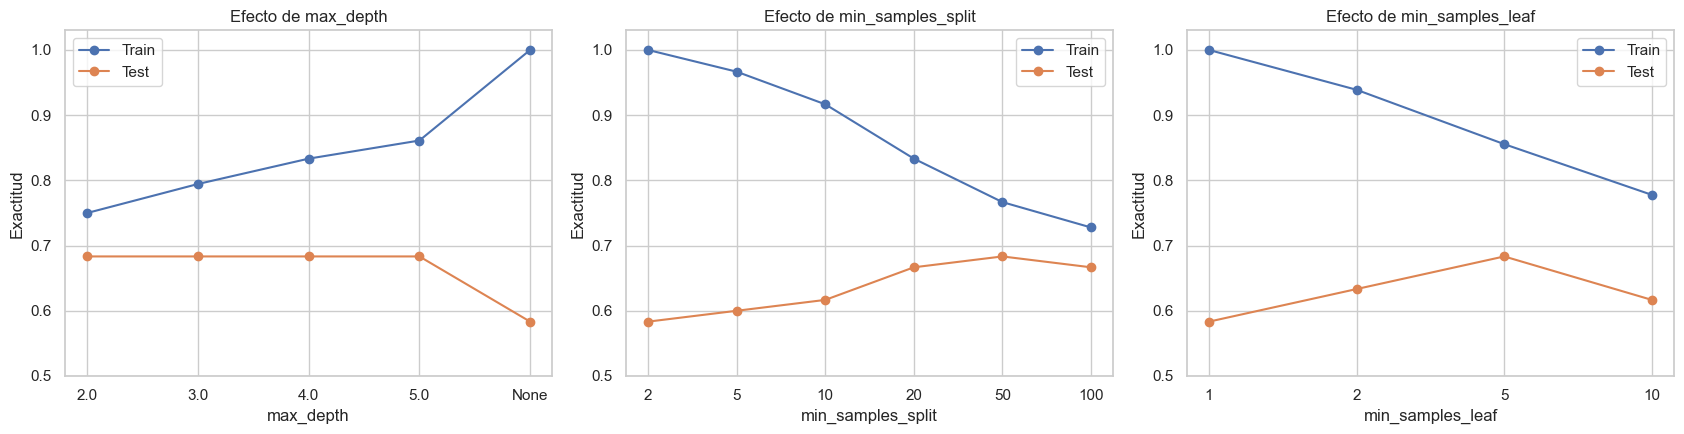

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

experimentos = [
    (resultados_depth, "max_depth", "Efecto de max_depth"),
    (resultados_split, "min_samples_split", "Efecto de min_samples_split"),
    (resultados_leaf, "min_samples_leaf", "Efecto de min_samples_leaf"),
]

for ax, (tabla, parametro, titulo) in zip(axes, experimentos):
    etiquetas = ["None" if pd.isna(v) else str(v) for v in tabla[parametro]]
    ax.plot(etiquetas, tabla["exactitud_train"], marker="o", label="Train")
    ax.plot(etiquetas, tabla["exactitud_test"], marker="o", label="Test")
    ax.set_title(titulo)
    ax.set_xlabel(parametro)
    ax.set_ylabel("Exactitud")
    ax.set_ylim(0.5, 1.03)
    ax.legend()

plt.tight_layout()
plt.show()

Cuando la restricción se hace más fuerte, el árbol tiende a perder profundidad y hojas. En este conjunto, los árboles completos aumentan mucho la exactitud de entrenamiento sin mejorar la prueba. Los resultados con `max_depth=2` y con `min_samples_leaf=5` muestran un equilibrio más razonable.

## 7. Número máximo de hojas

`max_leaf_nodes` limita directamente el número de regiones terminales. Esto no es igual a limitar la profundidad: un árbol puede tener ramas de longitudes distintas y respetar un mismo máximo de hojas.

,max_leaf_nodes,exactitud_train,exactitud_test,brecha_train_test,profundidad,hojas
0,3.0000,0.7500,0.6833,0.0667,2,3
1,5.0000,0.7778,0.6833,0.0944,3,5
2,8.0000,0.8111,0.6833,0.1278,4,8
3,12.0000,0.8611,0.6667,0.1944,7,12
4,NaN,1.0000,0.5833,0.4167,11,43


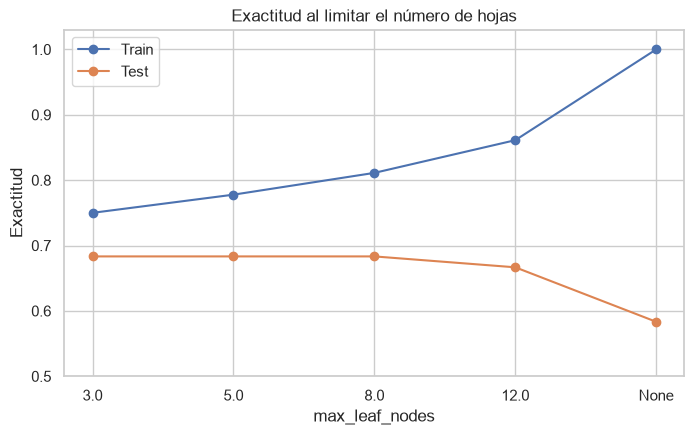

In [ ]:
resultados_max_hojas = experimento_parametro(
    "max_leaf_nodes", [3, 5, 8, 12, None]
)
display(resultados_max_hojas)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
etiquetas = [
    "None" if pd.isna(v) else str(v)
    for v in resultados_max_hojas["max_leaf_nodes"]
]
ax1.plot(etiquetas, resultados_max_hojas["exactitud_train"], marker="o", label="Train")
ax1.plot(etiquetas, resultados_max_hojas["exactitud_test"], marker="o", label="Test")
ax1.set_xlabel("max_leaf_nodes")
ax1.set_ylabel("Exactitud")
ax1.set_ylim(0.5, 1.03)
ax1.set_title("Exactitud al limitar el número de hojas")
ax1.legend()
plt.show()

Reducir `max_leaf_nodes` y reducir `max_depth` simplifican el árbol, pero lo hacen de manera diferente. `max_depth` corta todas las ramas a partir de un nivel. `max_leaf_nodes` permite que algunas ramas sean más profundas siempre que el total de hojas no supere el límite.

## 8. Poda por complejidad de coste

La poda busca minimizar

$$R_\alpha(T) = R(T) + \alpha|\widetilde{T}|.$$

El primer término favorece el ajuste a los datos y el segundo penaliza la cantidad de hojas. Al aumentar $\alpha$, mantener ramas adicionales se vuelve más costoso.

In [ ]:
arbol_base_poda = DecisionTreeClassifier(random_state=RANDOM_STATE)
arbol_base_poda.fit(X_train, y_train)
ruta_poda = arbol_base_poda.cost_complexity_pruning_path(X_train, y_train)
alphas_disponibles = ruta_poda.ccp_alphas

# Se toman valores repartidos en la ruta y se excluye el último,
# porque normalmente deja solamente la raíz.
indices_alpha = np.unique(
    np.linspace(0, max(len(alphas_disponibles) - 2, 0), 6, dtype=int)
)
alphas_elegidos = alphas_disponibles[indices_alpha]

filas_poda = []
modelos_poda = []
for alpha in alphas_elegidos:
    modelo = DecisionTreeClassifier(
        criterion="gini",
        ccp_alpha=float(alpha),
        random_state=RANDOM_STATE,
    )
    fila = metricas_arbol(modelo, f"alpha={alpha:.5f}")
    fila["ccp_alpha"] = float(alpha)
    filas_poda.append(fila)
    modelos_poda.append(modelo)

resultados_poda = pd.DataFrame(filas_poda)[[
    "ccp_alpha",
    "exactitud_train",
    "exactitud_test",
    "brecha_train_test",
    "profundidad",
    "hojas",
]]
display(resultados_poda)

,ccp_alpha,exactitud_train,exactitud_test,brecha_train_test,profundidad,hojas
0,0.0000,1.0000,0.5833,0.4167,11,43
1,0.0052,0.9778,0.6000,0.3778,11,34
2,0.0065,0.9556,0.6167,0.3389,11,27
3,0.0095,0.9000,0.6333,0.2667,8,19
4,0.0117,0.8333,0.6833,0.1500,5,10
5,0.0298,0.7278,0.6667,0.0611,1,2


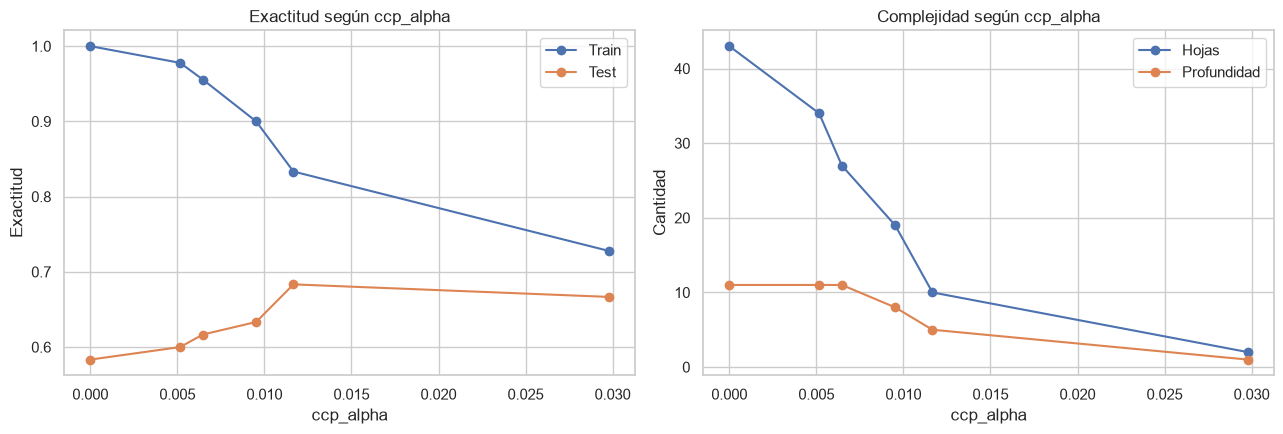

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(resultados_poda["ccp_alpha"], resultados_poda["exactitud_train"], marker="o", label="Train")
axes[0].plot(resultados_poda["ccp_alpha"], resultados_poda["exactitud_test"], marker="o", label="Test")
axes[0].set_title("Exactitud según ccp_alpha")
axes[0].set_xlabel("ccp_alpha")
axes[0].set_ylabel("Exactitud")
axes[0].legend()

axes[1].plot(resultados_poda["ccp_alpha"], resultados_poda["hojas"], marker="o", label="Hojas")
axes[1].plot(resultados_poda["ccp_alpha"], resultados_poda["profundidad"], marker="o", label="Profundidad")
axes[1].set_title("Complejidad según ccp_alpha")
axes[1].set_xlabel("ccp_alpha")
axes[1].set_ylabel("Cantidad")
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Árbol seleccionado

Se selecciona `max_depth=2`. En este caso alcanza el mejor resultado de prueba observado entre varios árboles sencillos, reduce claramente la brecha frente al árbol completo y conserva reglas fáciles de explicar. No se agrega poda por coste al modelo final (`ccp_alpha=0`) porque la restricción de profundidad ya controla su tamaño.

,modelo,exactitud_train,exactitud_test,brecha_train_test,profundidad,hojas
0,Árbol seleccionado,0.7500,0.6833,0.0667,2,4


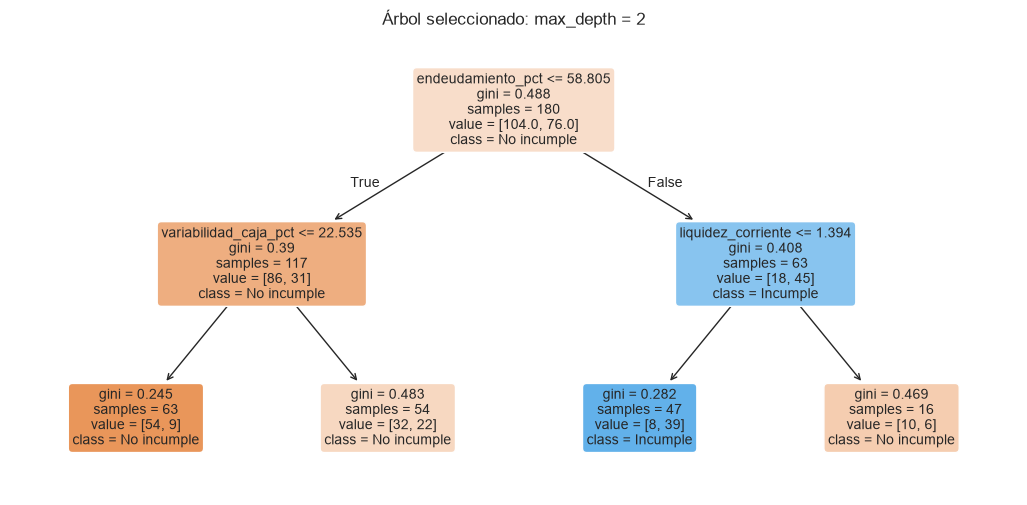

|--- endeudamiento_pct <= 58.81
|   |--- variabilidad_caja_pct <= 22.53
|   |   |--- class: 0
|   |--- variabilidad_caja_pct >  22.53
|   |   |--- class: 0
|--- endeudamiento_pct >  58.81
|   |--- liquidez_corriente <= 1.39
|   |   |--- class: 1
|   |--- liquidez_corriente >  1.39
|   |   |--- class: 0



In [ ]:
arbol_seleccionado = DecisionTreeClassifier(
    criterion="gini",
    max_depth=2,
    ccp_alpha=0.0,
    random_state=RANDOM_STATE,
)
metricas_arbol_seleccionado = metricas_arbol(
    arbol_seleccionado, "Árbol seleccionado"
)
display(pd.DataFrame([metricas_arbol_seleccionado]))

plt.figure(figsize=(13, 6))
plot_tree(
    arbol_seleccionado,
    feature_names=X.columns,
    class_names=["No incumple", "Incumple"],
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.title("Árbol seleccionado: max_depth = 2")
plt.show()

print(export_text(arbol_seleccionado, feature_names=list(X.columns), decimals=2))

### Interpretación de las primeras reglas

1. La primera separación se hace con el porcentaje de endeudamiento. Cuando supera aproximadamente 58.8 %, el árbol identifica un grupo de mayor riesgo.
2. Entre las empresas con endeudamiento más bajo, la variabilidad de caja sirve para crear dos grupos, aunque ambos terminan con predominio de no incumplimiento.
3. Entre las empresas más endeudadas, una liquidez corriente baja lleva a la clasificación de incumplimiento. Si la liquidez es mayor, el riesgo estimado disminuye.

Estas reglas tienen sentido financiero: un endeudamiento alto, combinado con poca liquidez, limita la capacidad de responder por las obligaciones de corto plazo.

# Mejora del modelo

In [26]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

class ConScoreLineal(BaseEstimator, TransformerMixin):
    """Agrega una columna con un score lineal aprendido solo con los datos de entrenamiento."""
    def fit(self, X, y):
        self.escalador = StandardScaler().fit(X)
        self.lineal = LogisticRegression(C=0.5).fit(self.escalador.transform(X), y)
        return self

    def transform(self, X):
        Z = np.asarray(X)
        score = self.lineal.decision_function(self.escalador.transform(Z))
        return np.column_stack([Z, score])

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)

arbol_mejorado = make_pipeline(
    ConScoreLineal(),
    DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
)

for nombre, modelo in {
    "Árbol actual (depth=2)": DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE),
    "Árbol + score lineal (depth=1)": arbol_mejorado,
}.items():
    exactitud = cross_val_score(modelo, X, y, cv=cv, scoring="accuracy")
    f1 = cross_val_score(modelo, X, y, cv=cv, scoring="f1")
    print(f"{nombre:32s} exactitud={exactitud.mean():.3f} ±{exactitud.std():.3f} | F1={f1.mean():.3f}")

Árbol actual (depth=2)           exactitud=0.701 ±0.065 | F1=0.643
Árbol + score lineal (depth=1)   exactitud=0.746 ±0.059 | F1=0.711


# Parte II. Máquinas de soporte vectorial

## 10. Estandarización

El escalador se ajusta únicamente con entrenamiento. El árbol puede trabajar con las unidades originales porque sus decisiones dependen de cortes. La SVM sí es sensible a la escala porque utiliza distancias, productos internos y márgenes.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

tabla_escalado = pd.DataFrame({
    "variable": X.columns,
    "media_train": scaler.mean_,
    "desviacion_train": scaler.scale_,
})
display(tabla_escalado)

,variable,media_train,desviacion_train
0,endeudamiento_pct,52.5775,17.9255
1,liquidez_corriente,1.1988,0.5490
2,antiguedad_empresa_anios,6.8306,3.9029
3,variabilidad_caja_pct,21.9442,9.4931
4,pagos_atrasados_12m,2.3500,1.6312


## 11. SVM lineal

Se prueban $C \in \{0.1, 1, 100\}$. Para cada modelo se calcula el número total de vectores de soporte, la norma de $w$ y el ancho total del margen $M=2/\|w\|_2$.

In [ ]:
filas_lineal = []
coeficientes_lineales = []
modelos_lineales = {}

for C in [0.1, 1, 100]:
    modelo = SVC(kernel="linear", C=C)
    modelo.fit(X_train_scaled, y_train)
    w = modelo.coef_[0]
    norma_w = np.linalg.norm(w)

    filas_lineal.append({
        "C": C,
        "exactitud_train": accuracy_score(y_train, modelo.predict(X_train_scaled)),
        "exactitud_test": accuracy_score(y_test, modelo.predict(X_test_scaled)),
        "vectores_soporte": int(modelo.n_support_.sum()),
        "norma_w": norma_w,
        "margen_total": 2 / norma_w,
    })

    fila_coeficientes = {"C": C}
    fila_coeficientes.update({
        f"w{i}": coeficiente
        for i, coeficiente in enumerate(w, start=1)
    })
    fila_coeficientes["b"] = modelo.intercept_[0]
    coeficientes_lineales.append(fila_coeficientes)
    modelos_lineales[C] = modelo

resultados_lineal = pd.DataFrame(filas_lineal)
tabla_coeficientes_lineales = pd.DataFrame(coeficientes_lineales)

print("Resultados de desempeño y margen:")
display(resultados_lineal)

print("Vector w e intercepto b para cada valor de C:")
display(tabla_coeficientes_lineales)


Resultados de desempeño y margen:


,C,exactitud_train,exactitud_test,vectores_soporte,norma_w,margen_total
0,0.1000,0.7667,0.7667,114,1.0590,1.8885
1,1.0000,0.7556,0.7667,103,1.1665,1.7145
2,100.0000,0.7611,0.7667,102,1.1764,1.7001


Vector w e intercepto b para cada valor de C:


,C,w1,w2,w3,w4,w5,b
0,0.1000,0.8495,-0.3694,-0.0559,0.1974,0.4705,-0.3409
1,1.0000,0.9309,-0.3877,-0.1078,0.2236,0.5314,-0.3513
2,100.0000,0.9453,-0.3797,-0.1140,0.2154,0.5355,-0.3458


In [ ]:
C_detalle = 0.1
svm_lineal = modelos_lineales[C_detalle]
w = svm_lineal.coef_[0]
b = svm_lineal.intercept_[0]

terminos = " + ".join([f"({coef:.4f})z{i}" for i, coef in enumerate(w, start=1)])
print("Correspondencia de variables:")
for i, nombre in enumerate(X.columns, start=1):
    print(f"z{i} = {nombre} estandarizada")

print("\nEcuación del hiperplano:")
print(f"{terminos} + ({b:.4f}) = 0")
print("\nBordes del margen:")
print(f"{terminos} + ({b:.4f}) = 1")
print(f"{terminos} + ({b:.4f}) = -1")

Correspondencia de variables:
z1 = endeudamiento_pct estandarizada
z2 = liquidez_corriente estandarizada
z3 = antiguedad_empresa_anios estandarizada
z4 = variabilidad_caja_pct estandarizada
z5 = pagos_atrasados_12m estandarizada

Ecuación del hiperplano:
(0.8495)z1 + (-0.3694)z2 + (-0.0559)z3 + (0.1974)z4 + (0.4705)z5 + (-0.3409) = 0

Bordes del margen:
(0.8495)z1 + (-0.3694)z2 + (-0.0559)z3 + (0.1974)z4 + (0.4705)z5 + (-0.3409) = 1
(0.8495)z1 + (-0.3694)z2 + (-0.0559)z3 + (0.1974)z4 + (0.4705)z5 + (-0.3409) = -1


Como hay cinco predictores, no se dibuja una línea bidimensional como si representara la frontera completa. La ecuación anterior describe el hiperplano en el espacio estandarizado de cinco dimensiones.

## 12. Kernel polinomial

Se estudian tres valores de `C` y grados 2, 3 y 4. `gamma` se mantiene en `scale` para observar de forma más clara el efecto de $C$ y del grado.

In [ ]:
filas_poly = []
modelos_poly = {}

for C in [0.1, 1, 100]:
    for grado in [2, 3, 4]:
        modelo = SVC(kernel="poly", C=C, degree=grado, gamma="scale")
        modelo.fit(X_train_scaled, y_train)
        filas_poly.append({
            "C": C,
            "grado": grado,
            "exactitud_train": accuracy_score(y_train, modelo.predict(X_train_scaled)),
            "exactitud_test": accuracy_score(y_test, modelo.predict(X_test_scaled)),
            "vectores_soporte": int(modelo.n_support_.sum()),
        })
        modelos_poly[(C, grado)] = modelo

resultados_poly = pd.DataFrame(filas_poly)
display(resultados_poly)

,C,grado,exactitud_train,exactitud_test,vectores_soporte
0,0.1000,2,0.5889,0.5833,154
1,0.1000,3,0.6833,0.6500,146
2,0.1000,4,0.6333,0.6167,156
3,1.0000,2,0.6389,0.6000,148
4,1.0000,3,0.7778,0.6833,124
5,1.0000,4,0.7111,0.5833,146
6,100.0000,2,0.6611,0.5667,140
7,100.0000,3,0.8778,0.7167,89
8,100.0000,4,0.8389,0.5333,114


La función de decisión del kernel polinomial tiene la forma

$$f(z)=\sum_{i \in SV}\alpha_i y_i(\gamma z_i^\top z+r)^d+b.$$

El grado controla la complejidad de las relaciones que puede representar. En los resultados se observa que aumentar el grado no garantiza una mejora en prueba.

## 13. Kernel RBF

Se combinan tres valores de `C` con $\gamma \in \{0.01, 0.1, 1\}$. Un valor grande de $\gamma$ hace que cada observación tenga una influencia más local y puede producir fronteras más irregulares.

In [ ]:
filas_rbf = []
modelos_rbf = {}

for C in [0.1, 1, 100]:
    for gamma in [0.01, 0.1, 1]:
        modelo = SVC(kernel="rbf", C=C, gamma=gamma)
        modelo.fit(X_train_scaled, y_train)
        filas_rbf.append({
            "C": C,
            "gamma": gamma,
            "exactitud_train": accuracy_score(y_train, modelo.predict(X_train_scaled)),
            "exactitud_test": accuracy_score(y_test, modelo.predict(X_test_scaled)),
            "vectores_soporte": int(modelo.n_support_.sum()),
        })
        modelos_rbf[(C, gamma)] = modelo

resultados_rbf = pd.DataFrame(filas_rbf)
display(resultados_rbf)

,C,gamma,exactitud_train,exactitud_test,vectores_soporte
0,0.1000,0.0100,0.5778,0.5833,153
1,0.1000,0.1000,0.6889,0.6333,154
2,0.1000,1.0000,0.5778,0.5833,168
3,1.0000,0.0100,0.7556,0.7333,141
4,1.0000,0.1000,0.7611,0.7333,124
5,1.0000,1.0000,0.9833,0.7000,165
6,100.0000,0.0100,0.7667,0.7333,108
7,100.0000,0.1000,0.9389,0.6667,99
8,100.0000,1.0000,1.0000,0.6667,154


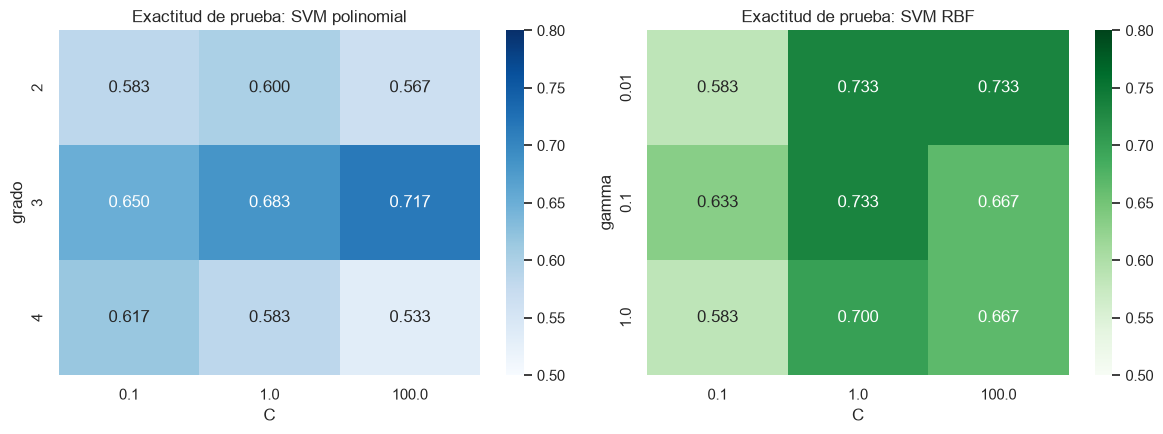

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

tabla_poly_heat = resultados_poly.pivot(index="grado", columns="C", values="exactitud_test")
sns.heatmap(tabla_poly_heat, annot=True, fmt=".3f", cmap="Blues", ax=axes[0], vmin=0.5, vmax=0.8)
axes[0].set_title("Exactitud de prueba: SVM polinomial")

tabla_rbf_heat = resultados_rbf.pivot(index="gamma", columns="C", values="exactitud_test")
sns.heatmap(tabla_rbf_heat, annot=True, fmt=".3f", cmap="Greens", ax=axes[1], vmin=0.5, vmax=0.8)
axes[1].set_title("Exactitud de prueba: SVM RBF")

plt.tight_layout()
plt.show()

La función de decisión del kernel RBF es

$$f(z)=\sum_{i \in SV}\alpha_i y_i\exp(-\gamma\|z-z_i\|^2)+b.$$

Con combinaciones grandes de `C` y `gamma`, la exactitud de entrenamiento aumenta mucho, pero la de prueba no mejora. Esto indica una frontera demasiado ajustada a los datos de entrenamiento.

# Parte III. Comparación árbol-SVM

## 14. Tabla final

Para la comparación se toma el mejor resultado razonable de cada familia. En caso de resultados similares, se prefiere la opción más sencilla y con menor brecha entre entrenamiento y prueba.

In [ ]:
mejor_poly_idx = resultados_poly["exactitud_test"].idxmax()
mejor_poly = resultados_poly.loc[mejor_poly_idx]

# C=1 y gamma=0.1 mantiene una brecha pequeña y usa menos SV
# que otras combinaciones RBF con la misma exactitud de prueba.
mejor_rbf = resultados_rbf.query("C == 1 and gamma == 0.1").iloc[0]
lineal_elegida = resultados_lineal.query("C == 0.1").iloc[0]

comparacion_final = pd.DataFrame([
    {
        "Modelo": "Árbol sin poda",
        "Complejidad relevante": f"profundidad={arbol_gini.get_depth()}, hojas={arbol_gini.get_n_leaves()}",
        "Exactitud train/test": f"{tabla_arboles_base.loc[0, 'exactitud_train']:.3f} / {tabla_arboles_base.loc[0, 'exactitud_test']:.3f}",
        "Elemento interpretable": "Reglas completas",
    },
    {
        "Modelo": "Árbol seleccionado",
        "Complejidad relevante": f"profundidad={arbol_seleccionado.get_depth()}, hojas={arbol_seleccionado.get_n_leaves()}, alpha=0",
        "Exactitud train/test": f"{metricas_arbol_seleccionado['exactitud_train']:.3f} / {metricas_arbol_seleccionado['exactitud_test']:.3f}",
        "Elemento interpretable": "Reglas cortas",
    },
    {
        "Modelo": "SVM lineal",
        "Complejidad relevante": f"C=0.1, margen={lineal_elegida['margen_total']:.3f}, SV={int(lineal_elegida['vectores_soporte'])}",
        "Exactitud train/test": f"{lineal_elegida['exactitud_train']:.3f} / {lineal_elegida['exactitud_test']:.3f}",
        "Elemento interpretable": "Hiperplano",
    },
    {
        "Modelo": "SVM polinomial",
        "Complejidad relevante": f"C={mejor_poly['C']:g}, grado={int(mejor_poly['grado'])}, SV={int(mejor_poly['vectores_soporte'])}",
        "Exactitud train/test": f"{mejor_poly['exactitud_train']:.3f} / {mejor_poly['exactitud_test']:.3f}",
        "Elemento interpretable": "Kernel polinomial",
    },
    {
        "Modelo": "SVM RBF",
        "Complejidad relevante": f"C=1, gamma=0.1, SV={int(mejor_rbf['vectores_soporte'])}",
        "Exactitud train/test": f"{mejor_rbf['exactitud_train']:.3f} / {mejor_rbf['exactitud_test']:.3f}",
        "Elemento interpretable": "Kernel RBF",
    },
])

display(comparacion_final)

,Modelo,Complejidad relevante,Exactitud train/test,Elemento interpretable
0,Árbol sin poda,"profundidad=11, hojas=43",1.000 / 0.583,Reglas completas
1,Árbol seleccionado,"profundidad=2, hojas=4, alpha=0",0.750 / 0.683,Reglas cortas
2,SVM lineal,"C=0.1, margen=1.889, SV=114",0.767 / 0.767,Hiperplano
3,SVM polinomial,"C=100, grado=3, SV=89",0.878 / 0.717,Kernel polinomial
4,SVM RBF,"C=1, gamma=0.1, SV=124",0.761 / 0.733,Kernel RBF


## 15. Revisión del modelo recomendado

La SVM lineal con `C=0.1` obtiene el mejor resultado de prueba y mantiene prácticamente el mismo desempeño en entrenamiento. Por eso se revisa también con matriz de confusión, precisión, recall y F1. Estas métricas son útiles porque en crédito importa especialmente identificar empresas que sí podrían incumplir.

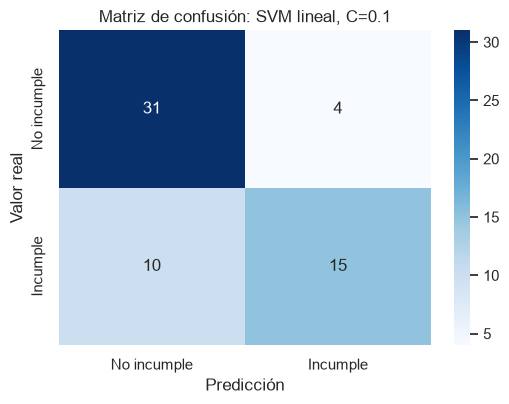

,exactitud,precision_clase_1,recall_clase_1,f1_clase_1
0,0.7667,0.7895,0.6000,0.6818


              precision    recall  f1-score   support

 No incumple       0.76      0.89      0.82        35
    Incumple       0.79      0.60      0.68        25

    accuracy                           0.77        60
   macro avg       0.77      0.74      0.75        60
weighted avg       0.77      0.77      0.76        60



In [ ]:
modelo_recomendado = modelos_lineales[0.1]
pred_recomendado = modelo_recomendado.predict(X_test_scaled)

matriz = confusion_matrix(y_test, pred_recomendado)
plt.figure(figsize=(5.5, 4.2))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No incumple", "Incumple"],
    yticklabels=["No incumple", "Incumple"],
)
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de confusión: SVM lineal, C=0.1")
plt.tight_layout()
plt.show()

metricas_adicionales = pd.DataFrame([{
    "exactitud": accuracy_score(y_test, pred_recomendado),
    "precision_clase_1": precision_score(y_test, pred_recomendado),
    "recall_clase_1": recall_score(y_test, pred_recomendado),
    "f1_clase_1": f1_score(y_test, pred_recomendado),
}])
display(metricas_adicionales)
print(classification_report(y_test, pred_recomendado, target_names=["No incumple", "Incumple"]))

## 16. Respuestas finales

### 1. ¿El árbol sin restricciones sobreajusta?

Sí. El árbol Gini alcanza 1.000 en entrenamiento y 0.583 en prueba. La brecha de aproximadamente 0.417, junto con sus 43 hojas, muestra que aprendió detalles muy específicos del entrenamiento.

### 2. ¿Qué parámetro de pre-poda tuvo mayor efecto sobre el tamaño?

`max_depth` produjo el cambio más directo: al pasar del árbol completo a profundidad 2, el tamaño bajó de 43 a 4 hojas. `min_samples_leaf` también redujo el árbol de forma importante, pero no controló la profundidad de manera tan directa.

### 3. ¿Qué efecto produjo aumentar `ccp_alpha`?

La profundidad y el número de hojas disminuyeron. La exactitud de entrenamiento también bajó. Al comienzo esto redujo sobreajuste, pero una poda demasiado fuerte terminó dejando un árbol muy simple.

### 4. ¿Qué relación se observó entre `C` y el margen lineal?

Al aumentar `C`, la norma de $w$ aumentó ligeramente y el margen se hizo más estrecho. Con `C=0.1` el margen total fue cercano a 1.889, mientras que con `C=100` fue cercano a 1.700.

### 5. ¿Cómo cambió el número de vectores de soporte?

El número total bajó de 114 con `C=0.1` a 102 con `C=100`. Un `C` pequeño acepta más observaciones dentro del margen o con error, por lo que más puntos participan como vectores de soporte.

### 6. ¿La frontera lineal parece insuficiente?

No hay evidencia fuerte de que sea insuficiente. La SVM lineal obtuvo 0.767 en prueba, por encima de las mejores configuraciones polinomial y RBF estudiadas. Los kernels no lineales aumentaron el ajuste de entrenamiento en algunos casos, pero no mejoraron la generalización.

### 7. ¿Qué efecto produjo `gamma` en RBF?

Con `gamma` alto la frontera se volvió más local. Por ejemplo, con `C=100` y `gamma=1` se llegó a 1.000 en entrenamiento, pero solo a 0.667 en prueba. Esto es una señal clara de sobreajuste.

### 8. ¿Cómo se controla la complejidad en árboles y SVM?

En los árboles se controla la estructura: profundidad, cantidad de hojas, mínimo de observaciones y poda. En SVM, `C` regula la penalización de errores, `gamma` controla el alcance de cada observación en RBF y el grado determina la complejidad del kernel polinomial. Estos parámetros no son equivalentes.

### 9. ¿Qué alternativa se selecciona?

Se selecciona la SVM lineal con `C=0.1`. Logró 0.767 tanto en entrenamiento como en prueba, tuvo el margen más ancho entre las SVM lineales probadas y superó a los kernels no lineales. El árbol seleccionado sigue siendo útil cuando se necesitan reglas simples para explicar una decisión de crédito, aunque su exactitud de prueba fue menor.

## 17. Conclusión

El árbol sin restricciones presentó sobreajuste, por lo que fue necesario controlar su tamaño. El árbol de profundidad 2 fue una alternativa fácil de explicar: relacionó principalmente endeudamiento, variabilidad de caja y liquidez con el riesgo de incumplimiento.

La SVM lineal con `C=0.1` obtuvo el mejor equilibrio general. Su resultado fue estable entre entrenamiento y prueba, y los kernels más complejos no aportaron una mejora real. Para este conjunto de datos, aumentar la complejidad permitió ajustar mejor el entrenamiento, pero no produjo mejores predicciones en observaciones nuevas.

Desde el punto de vista del problema, la elección final depende también del uso. La SVM lineal es preferible si se prioriza el desempeño predictivo. El árbol pequeño es útil si el analista necesita explicar la decisión mediante reglas directas.